# Subsystems

A subsystem is part of a diagram used as one block. A plain function wires
ordinary blocks and returns them as a `Subsystem`, naming the inner ports
that are its inputs and outputs. From outside it is one block; inside, every
block stays reachable and replaceable. No block types are duplicated: an
upconverter is a `Product`, a `Sine` and a filter, not a block of its own.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 48_000.0

## 1. A function returns a subsystem

The upconverter multiplies its input with a local oscillator and keeps the
upper sideband with a high-pass. `up.draw()` shows the inside; the blue
arrows are the subsystem's ports.

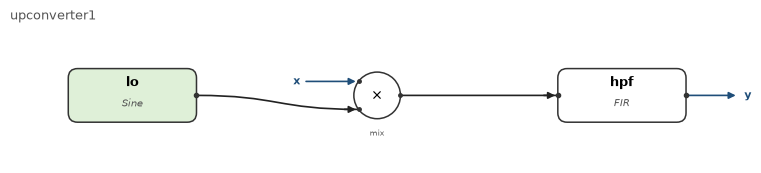

upconverter1 (upconverter)  |  3 blocks, 2 lines, 0 feedback

signal flow:
  lo ──▶ mix[x1] ──▶ hpf
ports:
  x ──▶ mix[x0]
  hpf[y] ──▶ y

blocks:
  [0] lo   Sine     10 kHz
  [1] mix  Product  ×
  [2] hpf  FIR      101 taps | ['upconverter1/mix', 'upconverter1/lo', 'upconverter1/hpf']


In [2]:
def upconverter(fc, cutoff, taps=101):
    mix = sl.Product(name="mix")
    sl.Sine(fc, name="lo") >> mix["x1"]
    hpf = mix >> sl.FIR(sig.firwin(taps, cutoff, pass_zero=False, fs=fs), name="hpf")
    return sl.Subsystem(inputs={"x": mix["x0"]}, outputs={"y": hpf})


up = upconverter(fc=10e3, cutoff=10e3)
up.draw()
plt.show()
print(up, "|", [m.name for m in up.members])

## 2. Used as one block

A 3 kHz tone through the upconverter: the product holds 7 and 13 kHz, the
high-pass keeps 13 kHz. In the diagram the subsystem is one box.

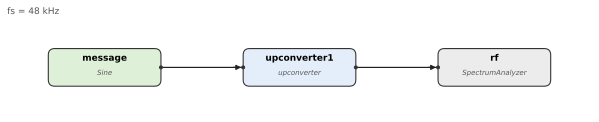

In [3]:
msg = sl.Sine(3e3, name="message")
spec = sl.SpectrumAnalyzer(nfft=2048, skip=200, name="rf")
msg >> up >> spec
d = sl.Diagram(spec, fs=fs)
d

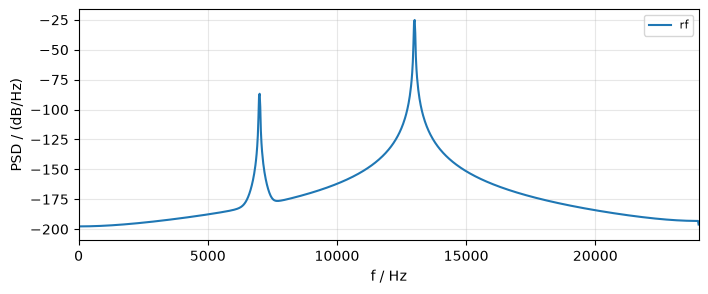

13 kHz -25.1 dB, image at 7 kHz -86.8 dB


In [4]:
def level(f):
    # psd / dB at the bin nearest f
    return 10 * np.log10(spec.psd[np.argmin(np.abs(spec.f - f))])


d.run(1.0)
fig, ax = plt.subplots(figsize=(8, 3))
spec.plot(ax=ax, max_hold=False)
ax.set_xlim(0, 24e3)
plt.show()
print(f"13 kHz {level(13e3):.1f} dB, image at 7 kHz {level(7e3):.1f} dB")

## 3. Reaching inside

Inner blocks are attributes, so parameters stay attributes: `up.lo.f`
retunes. `up.replace(old, new)` puts another block in the place of one,
with its lines; the diagram picks it up at the next run. Here a 6th-order
Butterworth high-pass replaces the FIR.

In [5]:
fir = {f: level(f) for f in (7e3, 13e3)}
sos = sig.butter(6, 10e3, "highpass", fs=fs, output="sos")
up.replace(up.hpf, sl.IIR(sos=sos, name="hpf"))
d.reset().run(1.0)
iir = {f: level(f) for f in (7e3, 13e3)}
for f in (7e3, 13e3):
    print(f"{f / 1e3:4.0f} kHz: FIR {fir[f]:6.1f} dB, IIR {iir[f]:6.1f} dB")

   7 kHz: FIR  -86.8 dB, IIR  -48.2 dB
  13 kHz: FIR  -25.1 dB, IIR  -25.2 dB


The FIR holds the image 62 dB below the wanted tone, the 6th-order
Butterworth 23 dB, with three biquads instead of 101 taps. The new block
sits where the old one was:

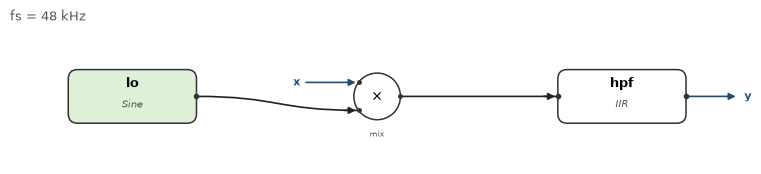

In [6]:
up.draw()
plt.show()

## 4. One input, several inner ports

An I/Q mixer feeds its input to two products. A list of ports makes one
subsystem input; one line in reaches both.

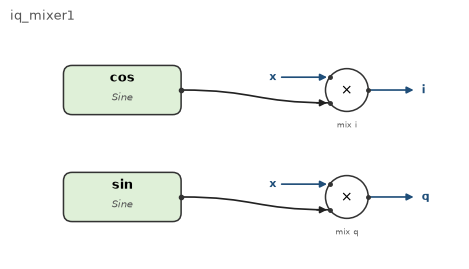

In [7]:
def iq_mixer(fc):
    mix_i, mix_q = sl.Product(name="mix i"), sl.Product(name="mix q")
    sl.Sine(fc, name="cos") >> mix_i["x1"]
    sl.Sine(fc, phase=-np.pi / 2, name="sin") >> mix_q["x1"]
    return sl.Subsystem(
        inputs={"x": [mix_i["x0"], mix_q["x0"]]},
        outputs={"i": mix_i, "q": mix_q},
    )


iq_mixer(10e3).draw()
plt.show()

## 5. Subsystems nest

A receiver from the I/Q mixer and two low-passes, recombined to complex
baseband: $2(i - jq)$ brings 13 kHz back to 3 kHz. Its inner subsystem
keeps its own box.

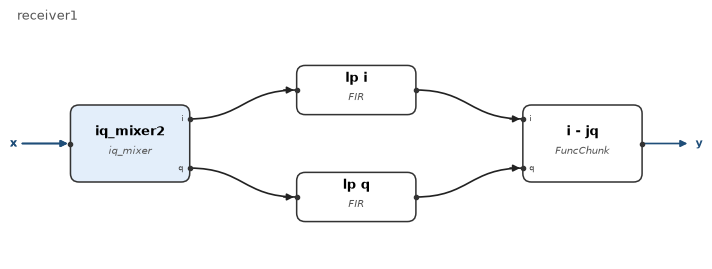

In [8]:
def receiver(fc, cutoff, taps=101):
    iq = iq_mixer(fc)
    lp = sig.firwin(taps, cutoff, fs=fs)
    bb = sl.FuncChunk(lambda i, q: 2 * (i - 1j * q), name="i - jq")
    iq["i"] >> sl.FIR(lp, name="lp i") >> bb["i"]
    iq["q"] >> sl.FIR(lp, name="lp q") >> bb["q"]
    return sl.Subsystem(inputs={"x": iq}, outputs={"y": bb})


rx = receiver(fc=10e3, cutoff=5e3)
rx.draw()
plt.show()

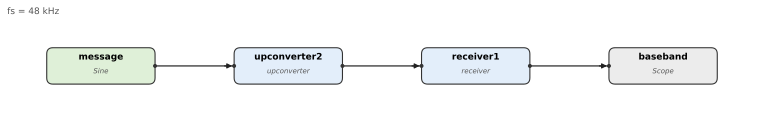

In [9]:
msg, tx = sl.Sine(3e3, name="message"), upconverter(fc=10e3, cutoff=10e3)
out = sl.Scope("baseband")
msg >> tx >> rx >> out
link = sl.Diagram(out, fs=fs)
link

baseband peak at 3.00 kHz


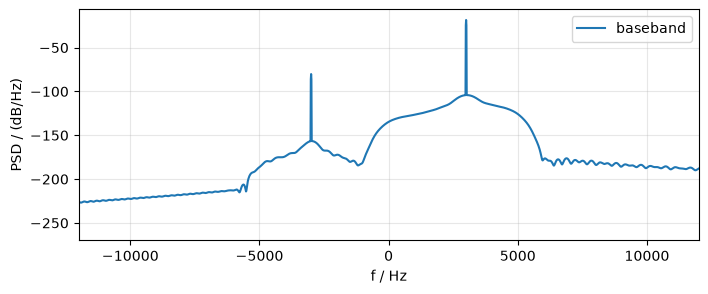

In [10]:
link.run(0.2)
f, P = out.psd()
print(f"baseband peak at {f[np.argmax(P)] / 1e3:.2f} kHz")
fig, ax = plt.subplots(figsize=(8, 3))
out.plot_psd(ax=ax)
ax.set_xlim(-12e3, 12e3)
plt.show()

## 6. Opened

`link.draw(expand=True)` opens every subsystem, nested ones too: their
blocks sit in a dashed frame titled with name and type. A frame only holds
its own blocks; where another block shares a column, the outline steps
around it. `to_dot`, `to_mermaid` and `to_text` take `expand=True` as well.

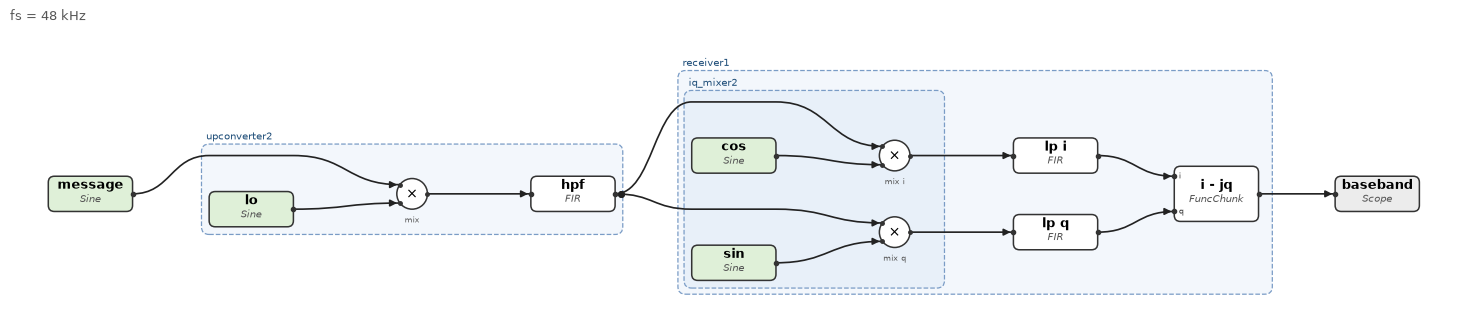

In [11]:
link.draw(expand=True)
plt.show()

## Summary

- `sl.Subsystem(inputs={...}, outputs={...})` turns wired blocks into one
  block; a function that returns it is a reusable part.
- Inner blocks by name (`up.lo.f`), replaced with `up.replace(old, new)`.
- An input given as a list feeds several inner ports; subsystems nest.
- `d.draw(expand=True)` shows the blocks inside, framed.
- A diagram runs the blocks inside directly: no extra blocks, no overhead.